# Regression with scikit-learn
---

In this lecture we will use many machine learning algorithms provided by [`scikit-learn`](https://scikit-learn.org/stable/), a standard machine learning library in Python, at least for non deep-learning tasks. In this notebook we will have a first hands-on with that library.

One basic conpect is the **fit-predict** paradigm, whereas *fit* fits data to a model (that means: learn a model from the data)  and *predict* uses the model to get results from the learned model with new data. This becomes very important later on in *supervised learning*.

### Linear Regression

Let us see how ML can be applied in practice with the help of `scikit-learn`, using an example provided by the Book [IPython Cookbook](https://ipython-books.github.io/).

For this, we will apply a linear regression model to **fit** a function to some noise-induced data. Our general objective is to be able to **predict** values on new data points using this approximated function. Basically this scenario belongs to supervised learning.

We start by making the usual and necessary imports:

In [11]:
import numpy as np
import sklearn.linear_model as lm # Linear regression model; conda install scikit-learn
import matplotlib.pyplot as plt

%matplotlib inline

A non-linear function $e^{3x}$, which we will simply call $f$, is going to act as the basis for our data:

In [12]:
def f(x):
    return np.exp(3 * x)

We are generating 200 data points to represent $f$ within the interval $[0, 2]$:

In [13]:
x_tr = np.linspace(0., 2, 200)
y_tr = f(x_tr)

We create some more data points within $[0, 1]$ with the help of $f$, but add some Gaussian noise this time around:

In [14]:
x = np.array([0, .1, .2, .5, .8, .9, 1])

np.random.seed(17) # Defining a seed value guarantees to get always (reproducible) random results. 
y = f(x) + np.random.randn(len(x))
print(x)
print(y)

[0.  0.1 0.2 0.5 0.8 0.9 1. ]
[ 1.27626589 -0.50476927  2.44601991  5.62700036 12.06036685 16.76637065
 19.97383863]


Let us plot our data using `matplotlib`. The actual function $f$ is displayed as a dotted curve, while our separate data points are represented as larger circles:

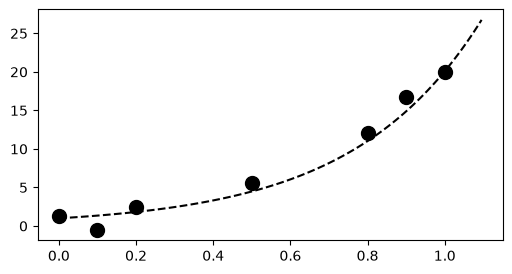

In [15]:
plt.figure(figsize=(6,3))
plt.plot(x_tr[:110], y_tr[:110], '--k')
plt.plot(x, y, 'ok', ms=10)

plt.show()

With the help of `scikit-learn` we will now perform [linear interpolation](https://en.wikipedia.org/wiki/Linear_interpolation) (which is also called *Linear Regression* in the context of ML). To do so, three steps must be followed:

1. We create an instance of the `LinearRegression` class (our model);
2. We *train* our model by finding the curve that best approximates our data (meaning we **fit** our model to the data)
3. We **predict** new values from our model (the fitted curve). If the predictions look like the dotted line above, this would be awesome!

*Note*: It is necessary to transform `x` and `x_tr` into column vectors, as it is a general convention, also in `scikit-learn`, that *observations (samples) are rows*, while *features are columns*.

In this little example, we are dealing with a single feature (our respective `x`-value) and seven observations (our noise-induced data points).

In [16]:
#print(x)
# Transposition
print(x[:, np.newaxis])

[[0. ]
 [0.1]
 [0.2]
 [0.5]
 [0.8]
 [0.9]
 [1. ]]


This is now 1D data, 7 rows (samples) and one column (feature)

Now the core part...

In [17]:
# Create the model
lr = lm.LinearRegression()
# Train the model
lr.fit(x[:, np.newaxis], y)
# Predict new values using the model
y_lr = lr.predict(x_tr[:, np.newaxis])

When plotting the results of our trained model, we will see the corresponding regression curve (green line):

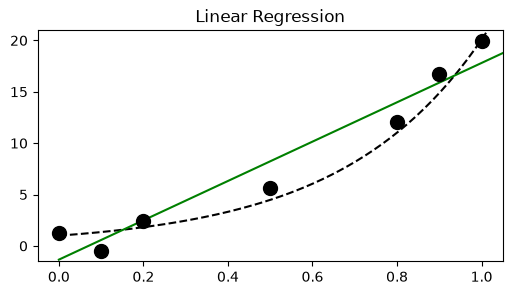

In [18]:
plt.figure(figsize=(6,3))
plt.plot(x_tr, y_tr, '--k')
plt.plot(x_tr, y_lr, 'g')
plt.plot(x, y, 'ok', ms=10)
plt.xlim(-0.05, 1.05)
plt.ylim(y.min() - 1, y.max() + 1)
plt.title("Linear Regression")

plt.show()

Obviously, our *linear* model does approximate the initial function $f$ rather poorly, which should not be surprising, given that $f$ is inherently *non-linear*. The example highlights a situation in which a trained model is not complex enough to properly fit the underlying data - an observation also called **underfitting**.
Therefore, we should try and apply a more complex non-linear method, namely [polynomial interpolation](https://en.wikipedia.org/wiki/Polynomial_interpolation). Interestingly enough, it is possible to still use linear regression in this case. However, it is necessary to increase the *dimensionality* this time around. That means we have to consider a polynomial as a *linear combination* of the power function up to the *degree* $d$ of the polynomial. Thus, we now get $d+1$ *features*, which are to be combined linearly to the function value. As a result, we are looking for the *coefficients* $a_i, i=1,\dots,d$ of the following  form:

$$
M_\theta(x) = a_0 + a_1 x^1 + a_2 x^2 + \cdots + a_d x^d
$$

With generally $n$ observations ($n=7$ in our case) we then obtain a (often under- or overdetermined) linear system of equations of the form:

$$
\left(
\matrix{
1 & x_1 & x_1^2 & \cdots & x_1^d\\
1 & x_2 & x_2^2 & \cdots & x_2^d\\
1 & x_3 & x_3^2 & \cdots & x_3^d\\
\vdots & \vdots & \vdots & \ddots & \vdots\\
1 & x_n & x_n^2 & \cdots & x_n^d
}
\right) \cdot
\left(
\matrix{ a_0 \\ \vdots \\ a_i \\ \vdots \\ a_d}
\right) =
\left(
\matrix{f_1 \\ \vdots \\ f_k \\ \vdots \\ f_n}
\right)
$$

It is now our goal to solve this system of linear equations "as well as possible" by minimizing the *error* we make, following some pre-defined criteria (often utilizing the [least squares method](https://en.wikipedia.org/wiki/Least_squares)).

The approach described here corresponds to polynomial interpolation using the [Vandermonde matrix](https://en.wikipedia.org/wiki/Vandermonde_matrix) for which NumPy provides the `np.vander` function. We will give it a try using polynomials of degree 2 and 5 (degree 1 would be the linear interpolation):

19.14 0.00
19.88 -0.74 0.00
-697.66 1776.57 -1555.07 550.93 -56.07 0.00


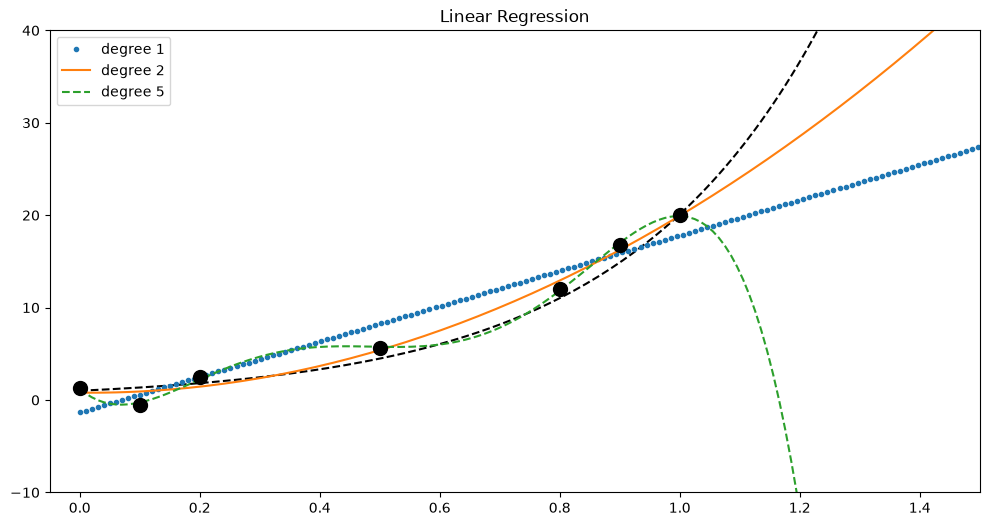

In [20]:
# Create a new model
lrp = lm.LinearRegression()

# Plot the baseline function f
plt.figure(figsize=(12,6))
plt.plot(x_tr, y_tr, '--k')

for deg, s in zip([1, 2, 5], ['.','-', '--']):
    lrp.fit(np.vander(x, deg + 1), y)  # Train
    y_lrp = lrp.predict(np.vander(x_tr, deg + 1)) # Predict
    plt.plot(x_tr, y_lrp, s, label='degree ' + str(deg))
    plt.legend(loc=2)
    plt.xlim(-0.05, 1.5)
    plt.ylim(-10, 40)
    # Print the model's coefficients
    print(' '.join(['%.2f' % c for c in lrp.coef_]))
plt.plot(x, y, 'ok', ms=10)
plt.title("Linear Regression")

plt.show()

As you can see, the fifth degree polynomial is very well adapted to the training data and matches our data points very accurately. However, outside the interval $[0,1]$ the polynomial does not resemble $f$ at all anymore. This effect is also called **overfitting** (i.e., the model has learned our data points by heart but cannot generalize to the underlying function $f$). Thus, our model is not suited to perform actual predictions.

### Advanced: Ridge Regression

Now that you have seen examples of underfitting (caused by a too-simple linear model) as well as overfitting (caused by a too-complex model), we will now use a different estimator called **Ridge Regression** using a technique called **regularization** to balance out both effects. 

Details are not important, in short, ridge regression works like linear regression except that it prevents the polynomial's coefficients from becoming too big (which happened in the previous example). By adding the regularization term in the loss function, ridge regression imposes some structure on the underlying model. More detailed information regarding this topic can be found [here](https://en.wikipedia.org/wiki/Tikhonov_regularization).

The message of using another regression is, that `scikit-learn` estimators always follow the **fit-predict-paradigm**, all we have to do is make minor adjustments to our code to get the new model running:

6.81 6.16 0.00
2.89 3.11 3.36 3.61 3.60 0.00


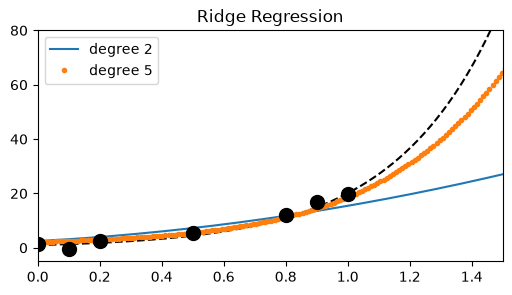

In [21]:
ridge = lm.Ridge()  #  Create new model: ridge regression
plt.figure(figsize=(6,3))
plt.plot(x_tr, y_tr, '--k')

for deg, s in zip([2, 5], ['-', '.']):
    ridge.fit(np.vander(x, deg + 1), y)  # New traning
    y_ridge = ridge.predict(np.vander(x_tr, deg + 1)) # New prediction
    plt.plot(x_tr, y_ridge, s, label='degree ' + str(deg))
    plt.legend(loc=2)
    plt.xlim(0, 1.5)
    plt.ylim(-5, 80)
    # Print the model's coefficients
    print(' '.join(['%.2f' % c for c in ridge.coef_]))

plt.plot(x, y, 'ok', ms=10)
plt.title("Ridge Regression")

plt.show()

This time, the fifth degree polynomial seems more precise than the simpler second degree polynomial (which now also causes underfitting). Thus, Ridge regression mitigates the overfitting issue. Also, observe how the fifth degree polynomial's coefficients are much smaller than they were previously.